In [1]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import torch
from scipy.special import softmax
vector.register_numba()
vector.register_awkward()
import os

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import mplhep as hep
hep.style.use(hep.style.ROOT)

import numba
import h5py
import yaml

import seaborn as sns

from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc
import onnxruntime    # to inference ONNX models, we use the ONNX Runtime

In [2]:
CMAP_10 = [
    "#3f90da",
    "#ffa90e",
    "#bd1f01",
    "#94a4a2",
    "#832db6",
    "#a96b59",
    "#e76300",
    "#b9ac70",
    "#717581",
    "#92dadd",
]

COLOR_ALIASES = {
    "CMS_blue": CMAP_10[0],        # Blue
    "CMS_orange": CMAP_10[1],      # Orange
    "CMS_red": CMAP_10[2],         # Red
    "CMS_gray": CMAP_10[3],        # Gray
    "CMS_purple": CMAP_10[4],      # Purple
    "CMS_brown": CMAP_10[5],       # Brown
    "CMS_dark_orange": CMAP_10[6], # Dark Orange
    "CMS_beige": CMAP_10[7],       # Beige
    "CMS_dark_gray": CMAP_10[8],   # Dark Gray
    "CMS_light_blue": CMAP_10[9]   # Light Blue
}

colors = {
    "ttHbb": COLOR_ALIASES["CMS_red"],
    "ttbb": COLOR_ALIASES["CMS_dark_orange"],
    "ttcc": COLOR_ALIASES["CMS_orange"],
    "ttlf": COLOR_ALIASES["CMS_blue"],
    "ttV": COLOR_ALIASES["CMS_brown"],
    "singleTop": COLOR_ALIASES["CMS_purple"],
}

labels = {
    "ttHbb": 1, 
    "ttbb": 2,
    "ttcc": 3,
    "ttlf": 4,
    "ttV": 5, 
    "singleTop": 6}

nice_labels = {
    "ttHbb" : "$t\\bar{t}H(b\\bar{b})$",
    "ttbb" : "$t\\bar{t}$+B",
    "ttcc" : "$t\\bar{t}$+C",
    "ttlf" : "$t\\bar{t}$+LF",
}

In [3]:
out_folder = "/eos/home-g/gbonomel/tth/spanet/models/multiclassifier_Run3_weights/spanet_output/plots/"

In [4]:
def plot_score(pred_label, score, label, ax, weights=None, title=None, mask=None, log=False, ylim=None, density=False, legend=True):
    if type(mask) != type(None):
        pred_label = pred_label[mask]
        if type(weights) != type(None):
            weights = weights[mask]
    if label in colors:
        color = colors[label]
    else:
        color = ax._get_lines.get_next_color()
    #if label in nice_labels:
    #    label = nice_labels[label]
    n, bins, patches = ax.hist(pred_label, bins=50, range=(0,1), weights=weights, histtype="step", linewidth=2, color=color, label=label, density=density)
    if legend:
        ax.legend(fontsize=15)
    ax.set_xlabel(f"{score} SPANet score")
    if density:
        ax.set_ylabel("A.U.")
    else:
        ax.set_ylabel("Counts")
    if log:
        ax.set_yscale("log")
    if ylim != None:
        ax.set_ylim(*ylim)
    if title:
        ax.set_title(title)
    return n, bins, patches

def plot_scores(true_labels, pred_labels, plot_dir=None, weights=None, title=None, mask=None, log=False, ylim=None, density=False):
    fig, axes = plt.subplots(2, 3, figsize=[20,14], dpi=100)
    for i, score in enumerate(labels):
        ax = axes[i // 3][i % 3]
        for j, label in enumerate(labels):
            mask_by_sample = true_labels[label]
            if type(mask) != type(None):
                mask_by_sample = mask_by_sample & mask
            legend = True #if score == "tthbb" else False][0]         
            if type(weights) != type(None):
                plot_score(pred_labels[score], score, label, mask=mask_by_sample, ax=ax, weights=weights, title=title, log=log, ylim=ylim, density=density, legend=legend)
            else:
                plot_score(pred_labels[score], score, label, mask=mask_by_sample, ax=ax, title=title, log=log, ylim=ylim, density=density, legend=legend)
        fig.tight_layout(pad=1.5)
    if plot_dir is not None:
        filename = os.path.join(plot_dir, "classification_scores.png")
        if weights is not None:
            filename = filename.replace(".png", "_weighted.png")
        if log:
            filename = filename.replace(".png", "_log.png")
        if density:
            filename = filename.replace(".png", "_normalised.png")
        plt.savefig(filename, dpi=300)

In [65]:
def plot_confusion_matrix(y_true, y_pred, plot_dir=None, norm=None, class_names=None, title=None, cmap='Blues', weights=None):

    # Compute confusion matrix with optional sample weights
    cm = confusion_matrix(y_true, y_pred, normalize=norm, sample_weight=weights)[1:, 1:] #remove 1st col and row bc empty

    if class_names is not None:
        labels = class_names
    else:
        labels = np.arange(cm.shape[0])
    
    # Plotting
    plt.figure(figsize=(12, 12), dpi=100)
    sns.heatmap(cm, annot=True, cmap=cmap, xticklabels=labels, yticklabels=labels.keys(), fmt=".2f")
    plt.title(title)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    if plot_dir is not None:
        if norm == "true":
            filename = os.path.join(plot_dir, "confusion_matrix_norm_true.png")
        elif norm == "pred":
            filename = os.path.join(plot_dir, "confusion_matrix_norm_pred.png")
        else:
            filename = os.path.join(plot_dir, "confusion_matrix.png")
        plt.savefig(filename, dpi=100)
    plt.show()

In [39]:
def plot_roc(true_label, pred_label, ax, label, weight=None):
    fpr, tpr, thresholds = roc_curve(true_label, pred_label, sample_weight=weight)
    i_sorted = np.argsort(fpr)
    AUC = auc(fpr[i_sorted], tpr[i_sorted])
    ax.plot(tpr, fpr, label=f"{label} AUC={round(AUC, 3)}")
    ax.set_yscale("log")
    ax.set_title(f"{label} score")
    ax.set_xlabel("Signal efficiency")
    ax.set_ylabel("Background efficiency")
    ax.legend()

def plot_rocs(true_labels, pred_labels, weight=None, plot_dir=None):
    fig, axes = plt.subplots(2, 3, figsize=[18,12])
    for i, label in enumerate(labels):
        ax = axes[i // 3][i % 3]#[i % 2][int(i / 2)]
        true_label = true_labels[label]
        pred_label = pred_labels[label]
        #plot_roc(true_label, pred_label, ax, label)
        plot_roc(true_label, pred_label, ax, label+" weighed", weight=weight)
    fig.tight_layout(pad=2.5)
    if plot_dir is not None:
        filename = os.path.join(plot_dir, "roc_curves.png")
        plt.savefig(filename, dpi=300)

In [62]:
def plot_correlation_matrix(numpy_array, plot_dir, feature_names=None, title="Correlation Matrix", annot=True, cmap="coolwarm"):
    """
    Plots the correlation matrix from a NumPy array and saves it to a file.
        numpy_array (np.ndarray): A NumPy array of shape [N, M], where M is the
                                   number of features.
        output (str): Path to the output PNG file.
        feature_names (list of str, optional): List of feature names to be used as
                                               labels for the plot. Defaults to None.
        annot (bool, optional): Whether to display correlation coefficients in the
                                heatmap. Defaults to True.
    """

    #num_features = numpy_array.shape[1]
    if feature_names is None:
        feature_names = [f'Feature {i+1}' for i in range(num_features)]
    
    df = pd.DataFrame(numpy_array[:, 1:], columns=feature_names) # dont consider numpy_array[:,0] because empty
    corr_matrix = df.corr()

    # Create the heatmap
    plt.figure(figsize=(12, 12), dpi=100)
    sns.heatmap(corr_matrix, annot=annot, cmap=cmap, xticklabels=feature_names, yticklabels=feature_names)
    plt.title(title)
    #plt.tight_layout()

    if plot_dir is not None:
        filename = os.path.join(plot_dir, "correlation_matrix.png")
        plt.savefig(filename, dpi=100)
    plt.show()
    plt.close()

In [45]:
def plot_cumulative_significance(true_scores, scores, weights, signal_index=None, bins=30, range=(0, 1), xlabel="Threshold", ylabel="$S/\\sqrt{B}$", plot_dir=None):
    """
    Plots the significance (S/sqrt(B)) as a function of score or any other variable.
        true_score (np.ndarray): True class labels of shape (N,).
        out_score (np.ndarray): Array of classifier outputs with shape (N, num_classes).
        weights (np.ndarray): Event weights of shape (N,).
        signal_class (int): Class label to consider as signal (default=1).
        output_path (str, optional): Path to save the figure. If None, it will not save.
    """

    if signal_index is None:
        signal_index = 1

    class_index = scores.shape[1]

    # save true scores for signal and background
    true_signal = (true_scores == signal_index)
    true_bkg = ~true_signal
    pred_sig_scores = scores[:,signal_index]

    # save the output score for the signal events that are predicted as signal 
    pred_scores = np.argmax(scores, axis=1)
    is_signal_pred = (pred_scores == signal_index)
    score_pred_signal = scores[is_signal_pred,signal_index]

    true_scores_selected = true_scores[is_signal_pred]
    weights_selected = weights[is_signal_pred]

    # cumulative significance vs threshold
    thresholds = np.linspace(0, 1, 100)
    cum_significance_pred = np.zeros_like(thresholds, dtype=float)
    cum_significance_true = np.zeros_like(thresholds, dtype=float)
    
    for i, thr in enumerate(thresholds):
        pass_signal = score_pred_signal > thr
        pass_true_signal = (pred_sig_scores > thr) & true_signal
        pass_true_bkg = (pred_sig_scores > thr) & true_bkg

        S_true_cum = np.sum(weights[pass_true_signal])
        B_true_cum = np.sum(weights[pass_true_bkg])
        cum_significance_true[i] = S_true_cum / np.sqrt(B_true_cum) if B_true_cum > 0 else 0
        
        S_pred_cum = np.sum(weights_selected[pass_signal & (true_scores_selected == 1)])
        B_pred_cum = np.sum(weights_selected[pass_signal & (true_scores_selected != 1)])
        cum_significance_pred[i] = S_pred_cum / np.sqrt(B_pred_cum) if B_pred_cum > 0 else 0  
    
    fig, ax = plt.subplots(figsize=[10,8])
    ax.plot(thresholds, cum_significance_pred, marker='o', color=CMAP_10[0], linestyle='-', label="Predicted as ttHbb")
    ax.plot(thresholds, cum_significance_true, marker='o', color=CMAP_10[1], linestyle='-', label="ttHbb node")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title("Cumulative Significance")
    ax.legend(fontsize=15)

    if plot_dir is not None:
        filename = os.path.join(plot_dir, "cumulative_significance.png")
        plt.savefig(filename, dpi=300)
    plt.show()

In [9]:
def compute_s_over_sqrtb(y_true, scores, weights, signal_index=None, bins=30, range=(0, 1)):
    if signal_index is None:
        signal_index = 1
    if isinstance(bins, int):
        bins = np.linspace(range[0], range[1], bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    s_over_sqrtb = np.zeros(len(bin_centers))
    for i, (low, high) in enumerate(zip(bins[:-1], bins[1:])):
        in_bin = (scores >= low) & (scores < high)
        S = np.sum(weights[in_bin & (y_true==signal_index)])     # Signal in bin
        B = np.sum(weights[in_bin & (y_true!=signal_index)]) # Background in bin
        s_over_sqrtb[i] = S / np.sqrt(B) if B > 0 else 0
    return np.array(s_over_sqrtb)

In [11]:
sess_options = onnxruntime.SessionOptions()

sess_options.intra_op_num_threads = 4
sess_options.intra_op_num_threads = 4
sess_options.execution_mode = onnxruntime.ExecutionMode.ORT_PARALLEL
sess_options.graph_optimization_level = onnxruntime.GraphOptimizationLevel.ORT_ENABLE_ALL


session = onnxruntime.InferenceSession(
    "/eos/home-g/gbonomel/tth/spanet/models/multiclassifier_Run3_weights/spanet_v2.onnx", 
    sess_options = sess_options,
    providers=['CUDAExecutionProvider', 'CPUExecutionProvider']
)
for input in session.get_inputs():
    print(f"{input.name}, {input.shape}")
    
for output in session.get_outputs():
    print(f"{output.name}, {output.shape}")


/cvmfs/sft.cern.ch/lcg/views/LCG_107_swan/x86_64-el9-gcc13-opt/lib/python3.11/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:115: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'CPUExecutionProvider'
  warnings.warn(


Jet_data, ['batch_size', 'num_Jet', 9]
Jet_mask, ['batch_size', 'num_Jet']
Met_data, ['batch_size', 'num_Met', 3]
Met_mask, ['batch_size', 'num_Met']
Lepton_data, ['batch_size', 'num_Lepton', 3]
Lepton_mask, ['batch_size', 'num_Lepton']
Event_data, ['batch_size', 'num_Event', 1]
Event_mask, ['batch_size', 'num_Event']
t1_assignment_probability, ['Expt1_assignment_probability_dim_0', 'Expt1_assignment_probability_dim_1', 'Expt1_assignment_probability_dim_2', 'Expt1_assignment_probability_dim_3']
t2_assignment_probability, ['Expt2_assignment_probability_dim_0', 'Expt2_assignment_probability_dim_1']
h_assignment_probability, ['Exph_assignment_probability_dim_0', 'Exph_assignment_probability_dim_1', 'Exph_assignment_probability_dim_2']
t1_detection_probability, ['Sigmoidt1_detection_probability_dim_0']
t2_detection_probability, ['Sigmoidt2_detection_probability_dim_0']
h_detection_probability, ['Sigmoidh_detection_probability_dim_0']
EVENT/signal, ['SoftmaxEVENT/signal_dim_0', 7]


In [12]:
h5_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/non_semileptonic_tthbb_export/h5_files/tthbb_genmatched_ttbb_tthbb_non_semilep_test_1088450.h5"
config = "/eos/home-g/gbonomel/tth/spanet/models/multiclassifier_Run3_weights/spanet_output/version_0/event.yaml"

In [13]:
f = h5py.File(h5_file, 'r')
f.keys()

<KeysViewHDF5 ['CLASSIFICATIONS', 'INPUTS', 'TARGETS', 'WEIGHTS']>

In [16]:
jet_data = f["INPUTS"]["Jet"]
met_data = f["INPUTS"]["Met"]
lepton_data = f["INPUTS"]["Lepton"]
event_data = f["INPUTS"]["Event"]
weights = f["WEIGHTS"]["weight"]

In [17]:
weights[()]

array([0.05217322, 0.05831229, 0.03531294, ..., 0.0230327 , 0.04069727,
       0.10741478], dtype=float32)

In [18]:
with open(config, 'r') as file:
    data = yaml.safe_load(file)

jet_inputs    = list(data['INPUTS']['SEQUENTIAL']['Jet'].keys())
met_inputs    = data['INPUTS']['GLOBAL']['Met']
lepton_inputs = data['INPUTS']['GLOBAL']['Lepton']
event_inputs  = data['INPUTS']['GLOBAL']['Event']    

In [19]:
jet_input = np.stack([jet_data[j][()] for j in jet_inputs], axis=2)
met_input = np.stack([met_data[j][()] for j in met_inputs], axis=1)[:,None,:]
lepton_input = np.stack([lepton_data[j][()] for j in lepton_inputs], axis=1)[:,None,:]
event_input = np.stack([event_data[j][()] for j in event_inputs], axis=1)[:,None,:]

In [20]:
jet_input[:,:,0] = np.log(1+ jet_input[:,:,0])
met_input[:,:,0] = np.log(1+ met_input[:,:,0])
lepton_input[:,:,0] = np.log(1+ lepton_input[:,:,0])

In [21]:
jet_mask = jet_data["MASK"][()]
met_mask = np.ones(shape=[met_input.shape[0], 1]) == 1
lepton_mask = met_mask
event_mask = met_mask

In [22]:
met_mask.shape

(1088450, 1)

In [23]:
batch_size = 2048

In [24]:
Nevents = jet_input.shape[0]
cl_out= np.empty((Nevents, 7))

for i in range(Nevents//batch_size):
    output = session.run(input_feed={
        "Jet_data": jet_input[i*batch_size: (i+1)*batch_size],
        "Jet_mask": jet_mask[i*batch_size: (i+1)*batch_size],
        "Met_data": met_input[i*batch_size: (i+1)*batch_size],
        "Met_mask": met_mask[i*batch_size: (i+1)*batch_size],
        "Lepton_data": lepton_input[i*batch_size: (i+1)*batch_size],
        "Lepton_mask": lepton_mask[i*batch_size: (i+1)*batch_size],
        "Event_data": event_input[i*batch_size: (i+1)*batch_size],
        "Event_mask": event_mask[i*batch_size: (i+1)*batch_size],
        }, output_names=["EVENT/signal"]
               )
    cl_out[i*batch_size: (i+1)*batch_size] = output[0]

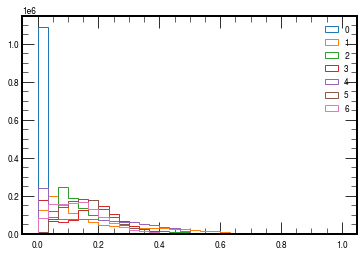

In [15]:
for i in range(7):
    plt.hist(cl_out[:,i], range=(0,1), bins=30, histtype='step', label=f"{i}")
plt.legend()
#plt.hist(cl_out[:,0])SoftmaxEVENT

(array([366190., 261583., 132816.,  87996.,  71540.,  62621.,  53262.,
         32731.,  17483.,   2228.]),
 array([0.        , 0.07500702, 0.15001404, 0.22502106, 0.30002809,
        0.37503511, 0.45004213, 0.52504915, 0.60005617, 0.67506319,
        0.75007021]),
 <BarContainer object of 10 artists>)

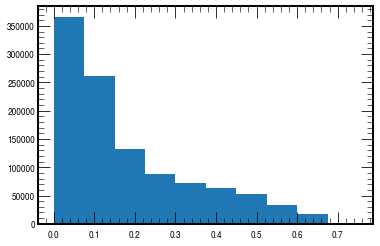

In [16]:
plt.hist(cl_out[:,1])

(array([2.78636e+05, 4.38771e+05, 1.96995e+05, 9.79880e+04, 4.22520e+04,
        1.91430e+04, 9.08300e+03, 4.31600e+03, 1.17900e+03, 8.70000e+01]),
 array([0.        , 0.08700274, 0.17400548, 0.26100823, 0.34801097,
        0.43501371, 0.52201645, 0.6090192 , 0.69602194, 0.78302468,
        0.87002742]),
 <BarContainer object of 10 artists>)

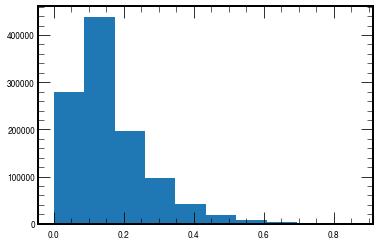

In [17]:
plt.hist(cl_out[:,2])

In [26]:
f.keys()

<KeysViewHDF5 ['CLASSIFICATIONS', 'INPUTS', 'TARGETS', 'WEIGHTS']>

In [27]:
y_true = f["CLASSIFICATIONS"]["EVENT"]["signal"][()]

In [28]:
y_pred = np.argmax(cl_out, axis=1)

In [29]:
y_true

array([2, 3, 2, ..., 3, 4, 3])

In [30]:
cl_out.shape[1]

7

In [31]:
true_labels = {}
pred_labels = {}
for label, index in labels.items():
    true_labels[label] = np.array(y_true == index)
    pred_labels[label] = np.array(cl_out[:,index])

In [32]:
true_labels

{'ttHbb': array([False, False, False, ..., False, False, False]),
 'ttbb': array([ True, False,  True, ..., False, False, False]),
 'ttcc': array([False,  True, False, ...,  True, False,  True]),
 'ttlf': array([False, False, False, ..., False,  True, False]),
 'ttV': array([False, False, False, ..., False, False, False]),
 'singleTop': array([False, False, False, ..., False, False, False])}

In [33]:
cl_out[:,1]

array([0.44111463, 0.16993007, 0.0346954 , ..., 0.        , 0.        ,
       0.        ])

In [34]:
region_mask = np.argmax(cl_out, axis=1) == 1
region_mask.shape

(1088450,)

In [35]:
true_labels["ttHbb"]

array([False, False, False, ..., False, False, False])

In [36]:
pred_labels

{'ttHbb': array([0.44111463, 0.16993007, 0.0346954 , ..., 0.        , 0.        ,
        0.        ]),
 'ttbb': array([0.37364459, 0.12914154, 0.07916912, ..., 0.        , 0.        ,
        0.        ]),
 'ttcc': array([0.03597337, 0.28916511, 0.0704277 , ..., 0.        , 0.        ,
        0.        ]),
 'ttlf': array([0.00726404, 0.13841654, 0.01984588, ..., 0.        , 0.        ,
        0.        ]),
 'ttV': array([0.11521715, 0.19084866, 0.51948291, ..., 0.        , 0.        ,
        0.        ]),
 'singleTop': array([0.02678624, 0.0824981 , 0.27637896, ..., 0.        , 0.        ,
        0.        ])}

In [32]:
weights.shape

(1088450,)

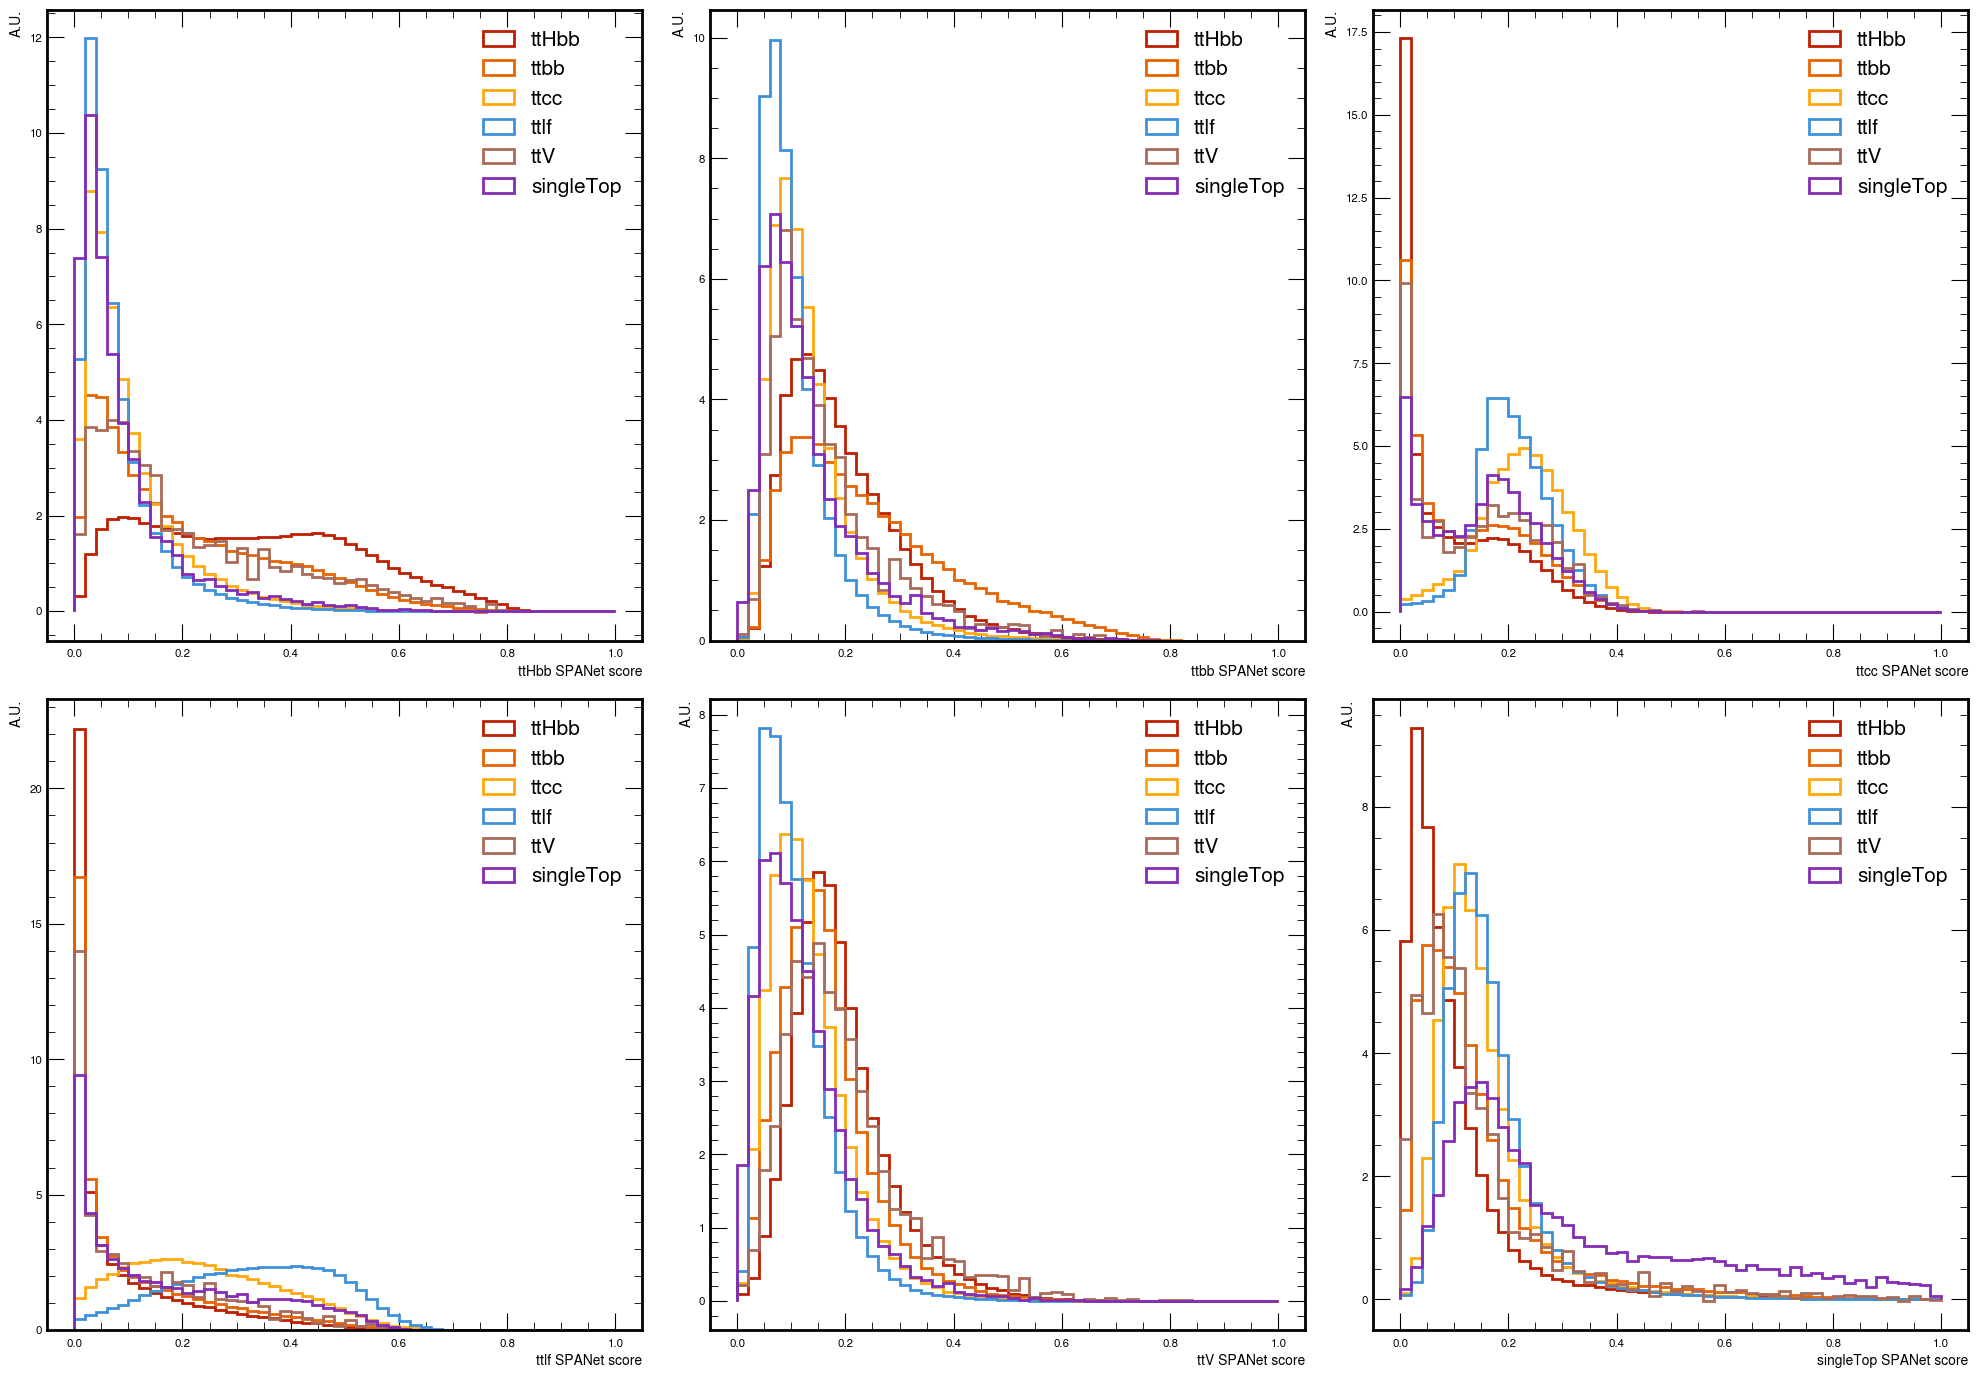

In [104]:
plot_scores(true_labels, pred_labels, weights=weights, plot_dir=out_folder, density=True) # mask by sample

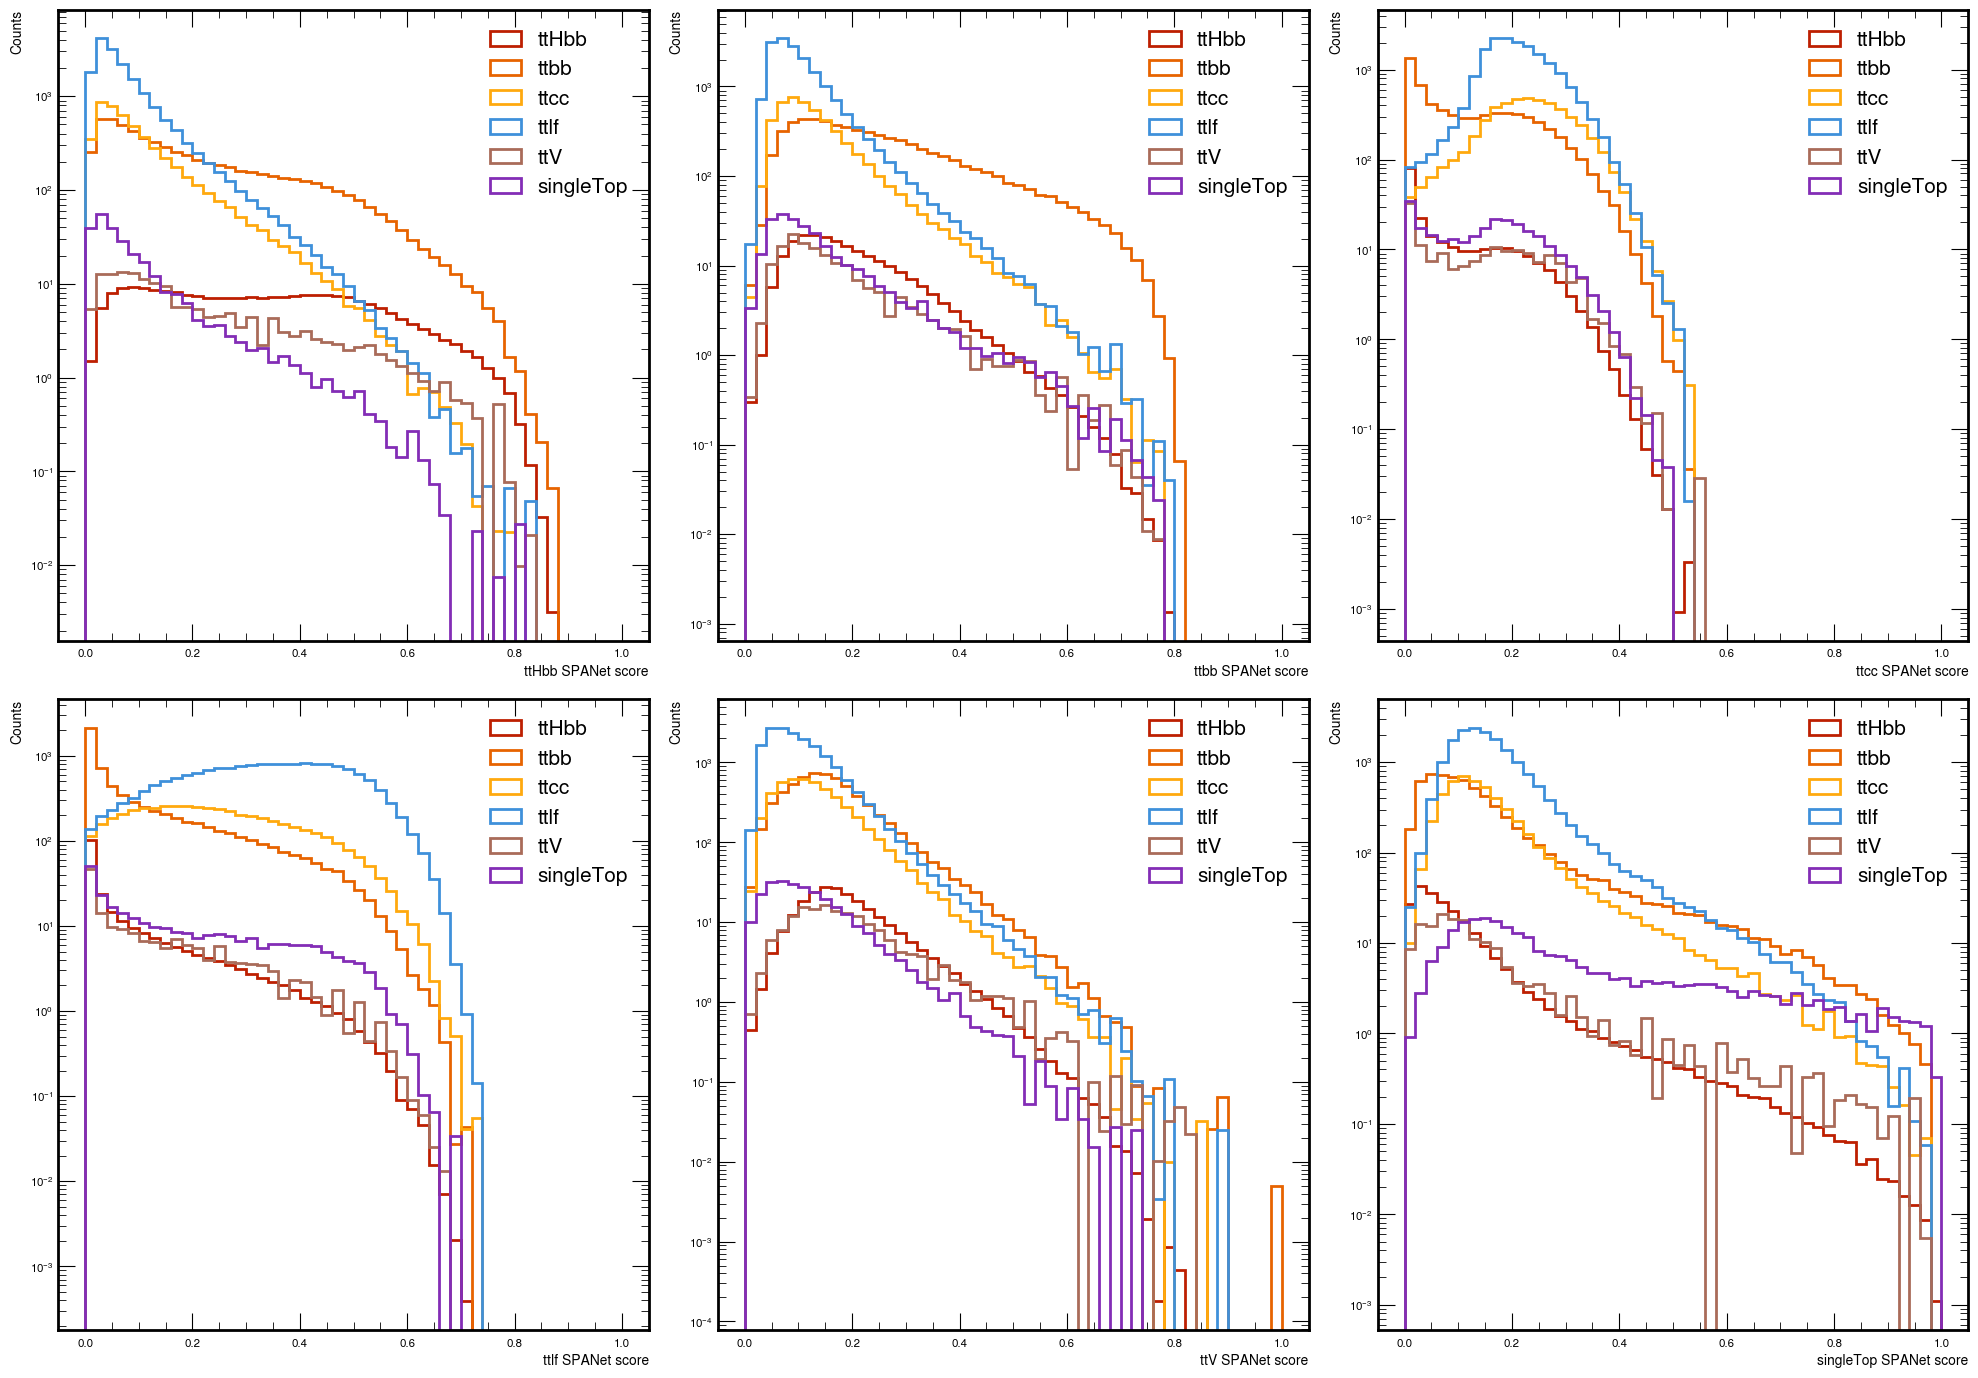

In [105]:
plot_scores(true_labels, pred_labels, weights=weights, plot_dir=out_folder, log=True) # mask by sample

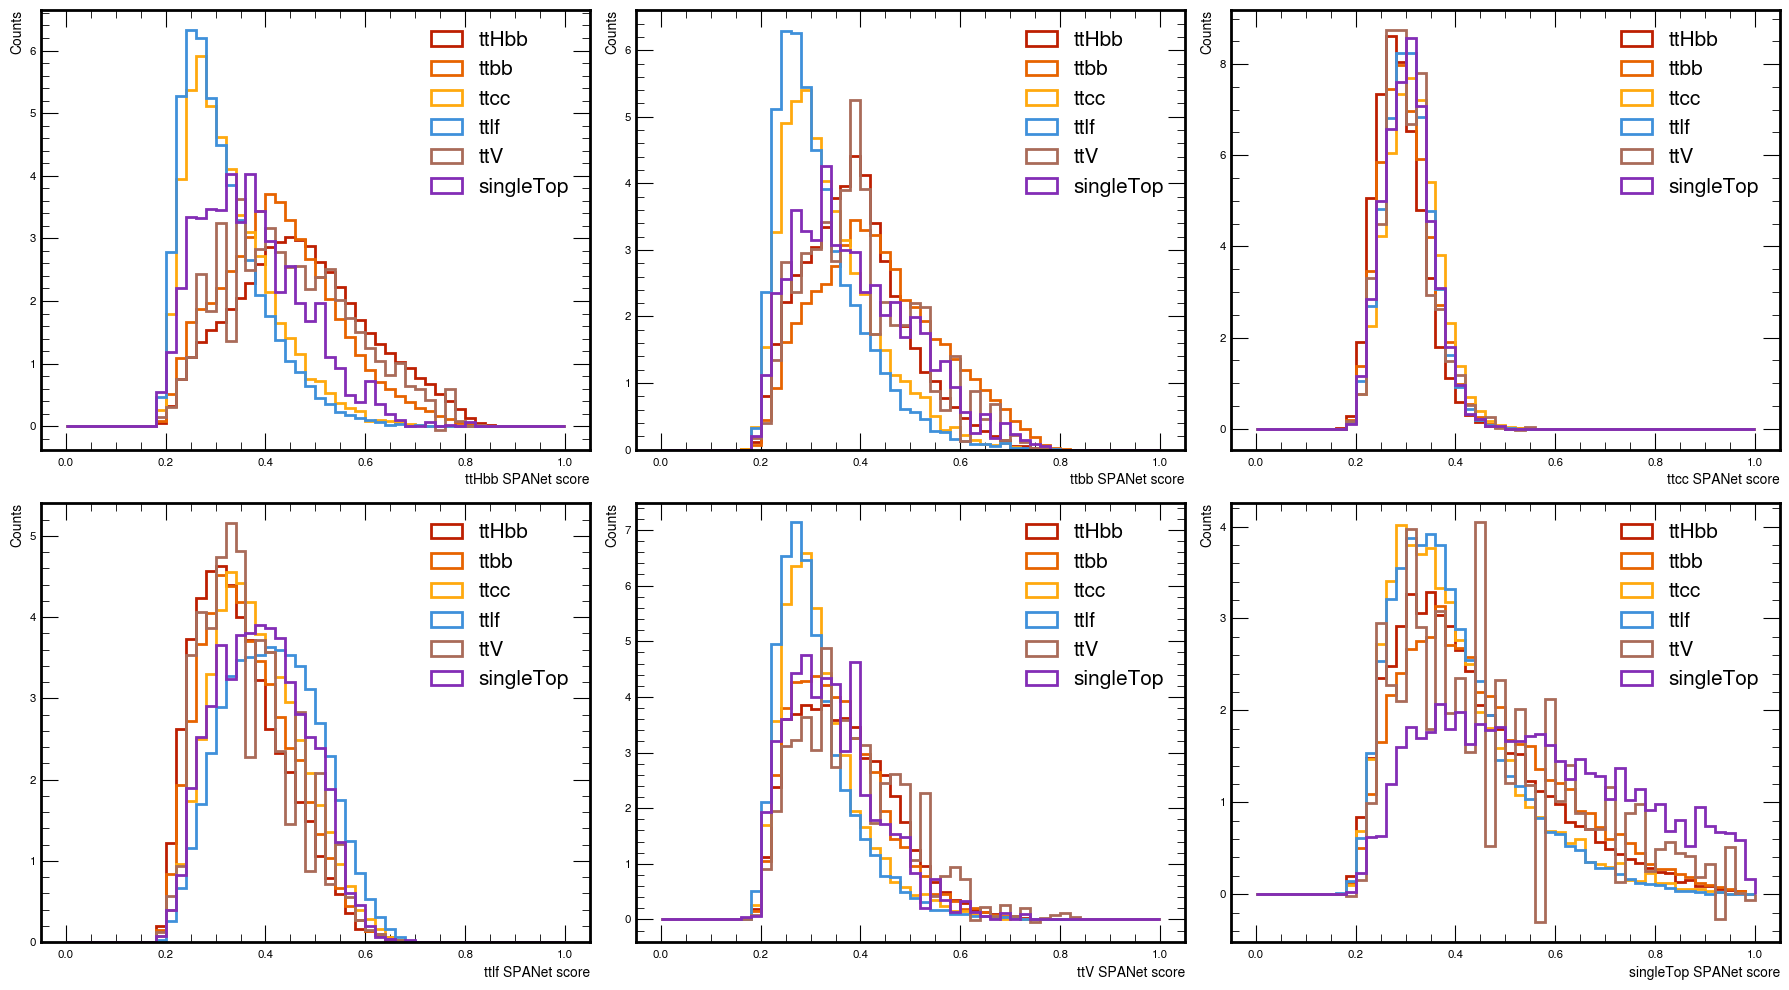

In [41]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=100)
axs = axs.flatten()
for i, (score, class_index) in enumerate(labels.items()):
    ax = axs[i]
    region_mask = np.argmax(cl_out, axis=1) == class_index
    for label, label_index in labels.items():
        mask = y_true == label_index
        color = colors[label]
        ax.hist(cl_out[mask & region_mask, class_index],
                bins=50, range=(0, 1),
                weights=weights[mask & region_mask],
                histtype="step", linewidth=2,
                color=color, label=label, density=True)
    ax.set_xlabel(f"{score} SPANet score")
    ax.set_ylabel("Counts")
    ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig(out_folder + "classification_scores_pred_region_weighed_normalised.png", dpi=300)
plt.show()

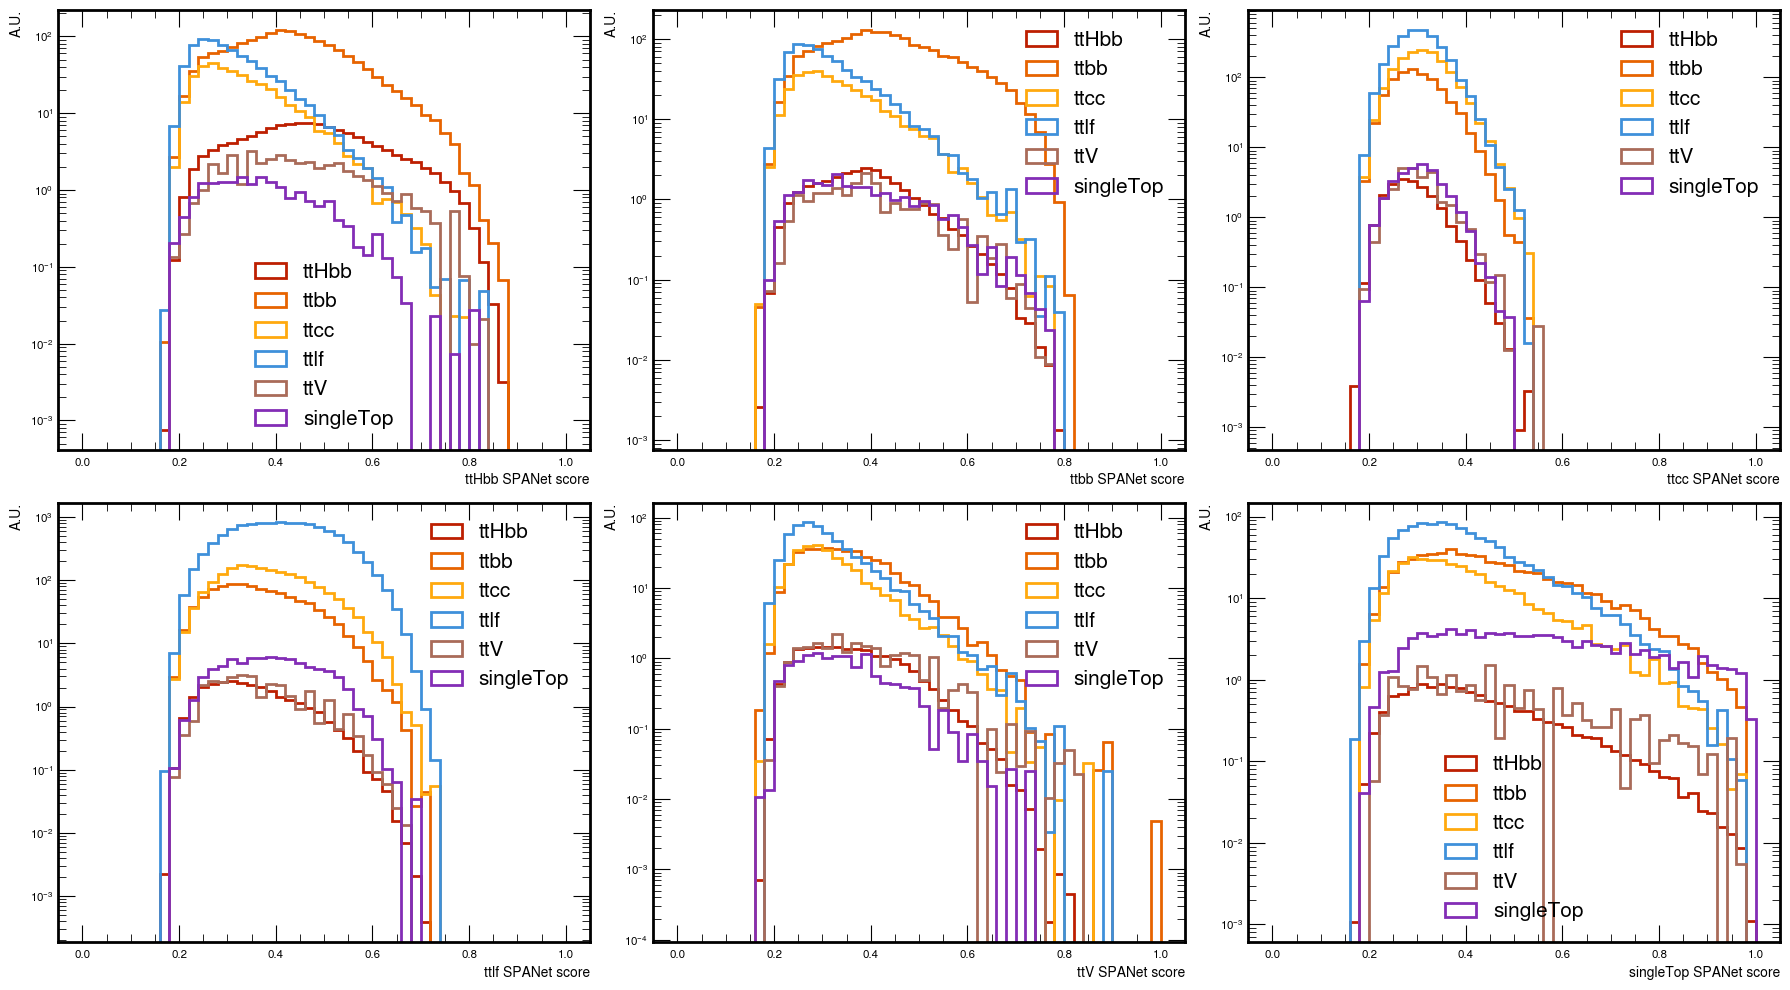

In [42]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=100)
axs = axs.flatten()
for i, (score, class_index) in enumerate(labels.items()):
    ax = axs[i]
    region_mask = np.argmax(cl_out, axis=1) == class_index
    for label, label_index in labels.items():
        mask = y_true == label_index
        color = colors[label]
        ax.hist(cl_out[mask & region_mask, class_index],
                bins=50, range=(0, 1),
                weights=weights[mask & region_mask],
                histtype="step", linewidth=2,
                color=color, label=label)
    ax.set_xlabel(f"{score} SPANet score")
    ax.set_ylabel("A.U.")
    ax.set_yscale("log")
    ax.legend(fontsize=15)
plt.tight_layout()
plt.savefig(out_folder + "classification_scores_pred_region_weighed_log.png", dpi=300)
plt.show()

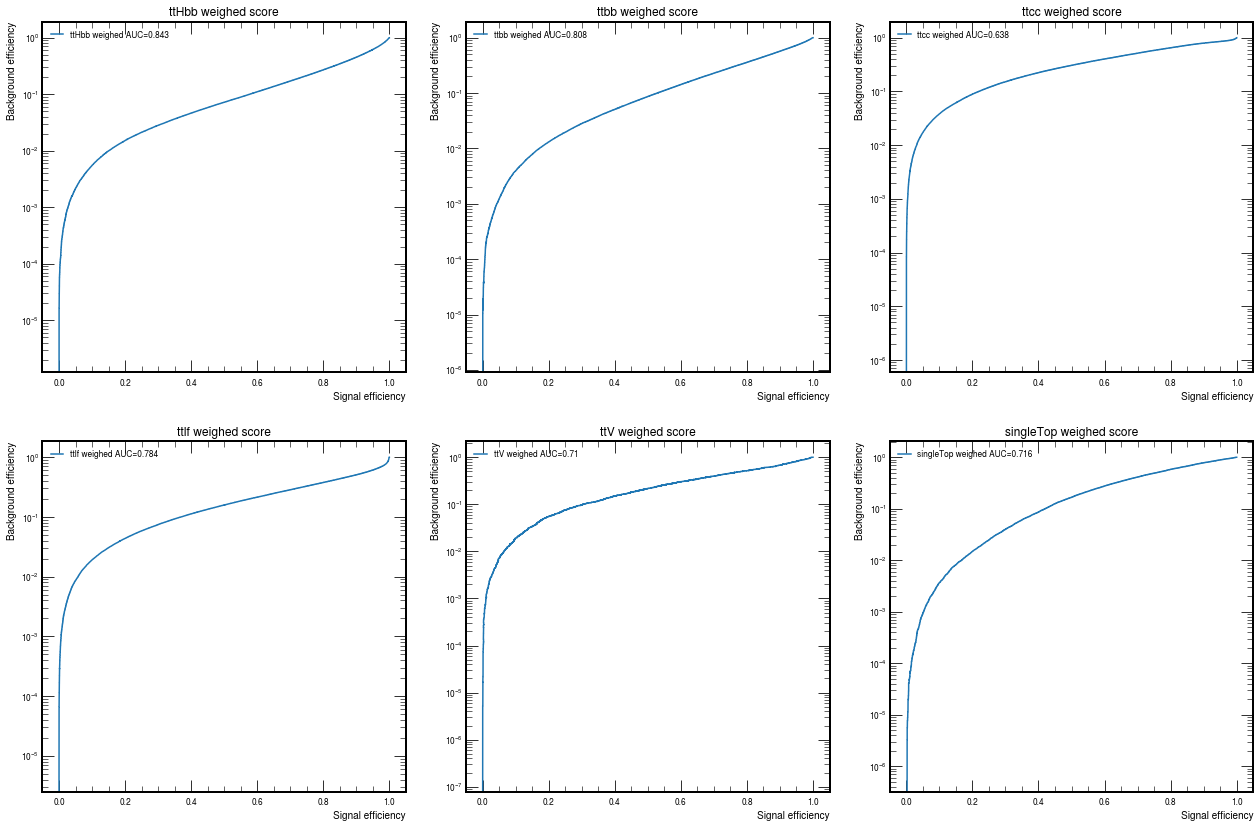

In [40]:
plot_rocs(true_labels, pred_labels, plot_dir=out_folder, weight=weights[:])

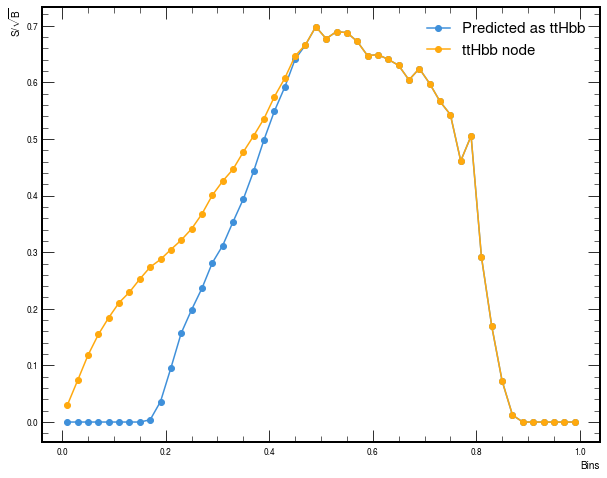

In [44]:
signal_index = labels["ttHbb"]
n_bin = 50
bins = np.linspace(0, 1, n_bin+1)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
predicted_as_signal = (y_pred == signal_index)
y_true_predicted_signal = y_true[predicted_as_signal]
scores_predicted_signal = cl_out[predicted_as_signal, signal_index]
weights_predicted_signal = weights[predicted_as_signal]
s_over_sqrtb_tthbb = compute_s_over_sqrtb(y_true_predicted_signal, scores_predicted_signal, weights_predicted_signal, bins=n_bin)
s_over_sqrtb = compute_s_over_sqrtb(y_true, cl_out[:, signal_index], weights, bins=n_bin)
fig, ax = plt.subplots(figsize=[10,8])
ax.plot(bin_centers, s_over_sqrtb_tthbb, marker='o', color=CMAP_10[0], linestyle='-', label="Predicted as ttHbb")
ax.plot(bin_centers, s_over_sqrtb, marker='o', color=CMAP_10[1], linestyle='-', label="ttHbb node")
ax.set_xlabel("Bins")
ax.set_ylabel("$S/\\sqrt{B}$")
ax.legend(fontsize=15)
fig.savefig(out_folder + "signal_significance.png", dpi=100)

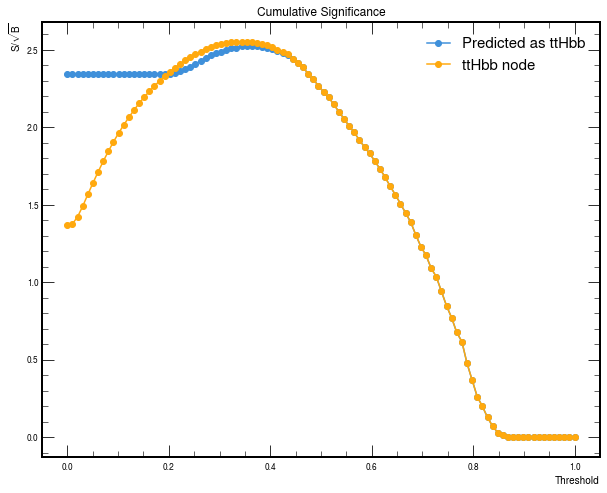

In [49]:
plot_cumulative_significance(y_true, cl_out, weights, plot_dir=out_folder)

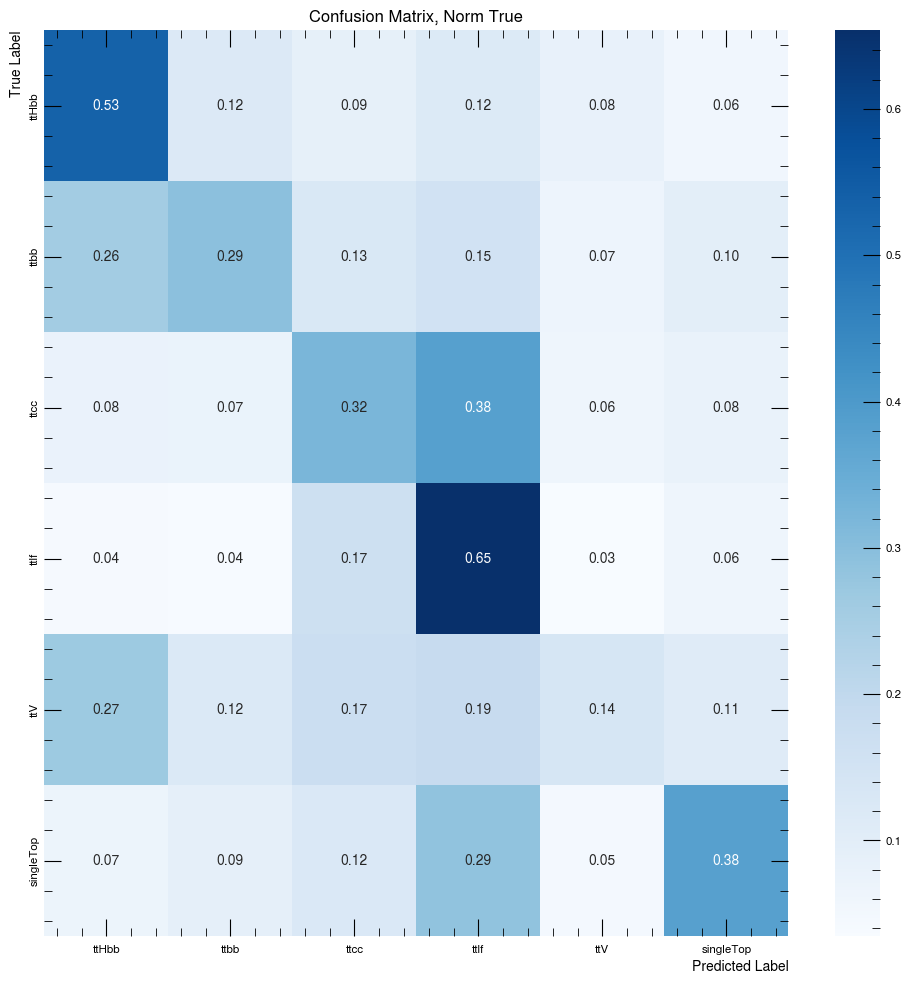

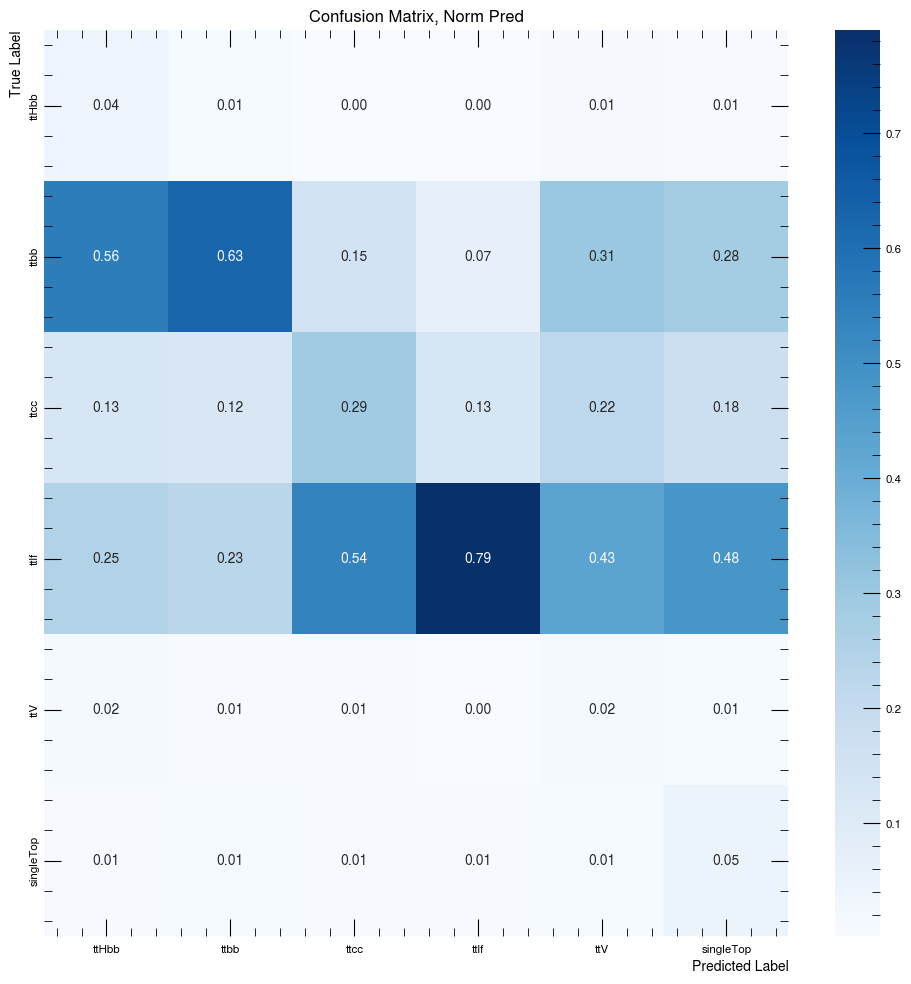

In [66]:
plot_confusion_matrix(y_true, y_pred, plot_dir=out_folder, norm="true", title="Confusion Matrix, Norm True", class_names=labels, weights=weights)
plot_confusion_matrix(y_true, y_pred, plot_dir=out_folder, norm="pred", title="Confusion Matrix, Norm Pred", class_names=labels, weights=weights)

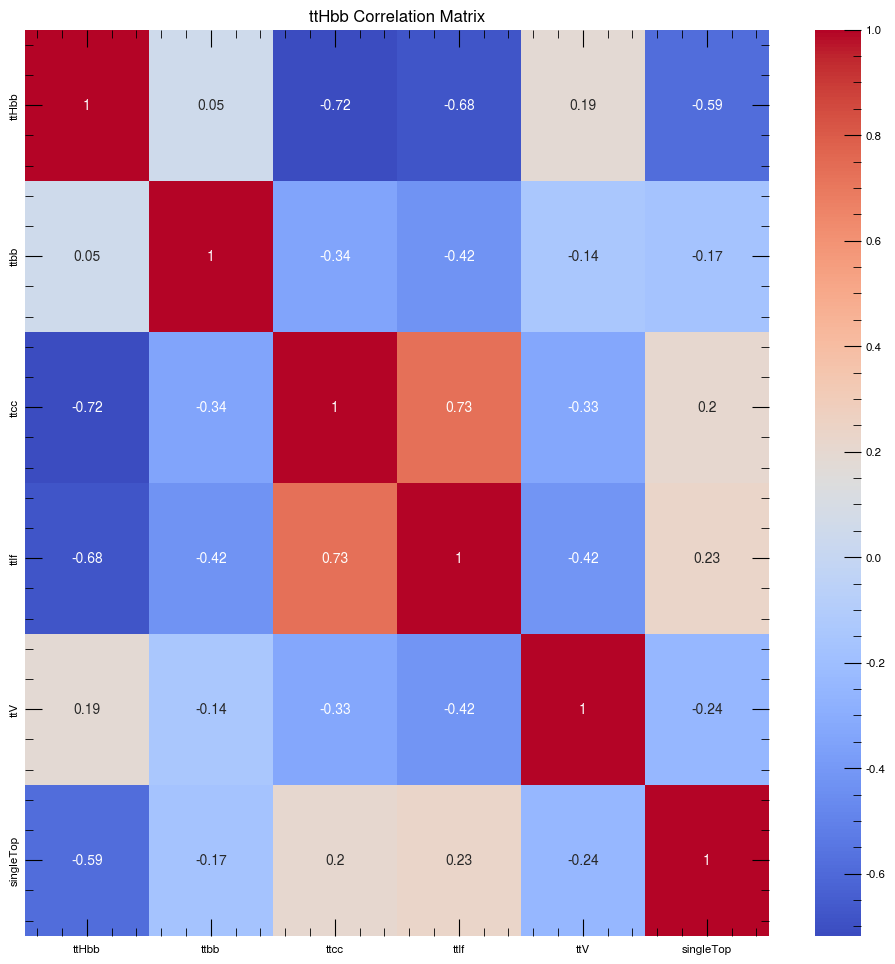

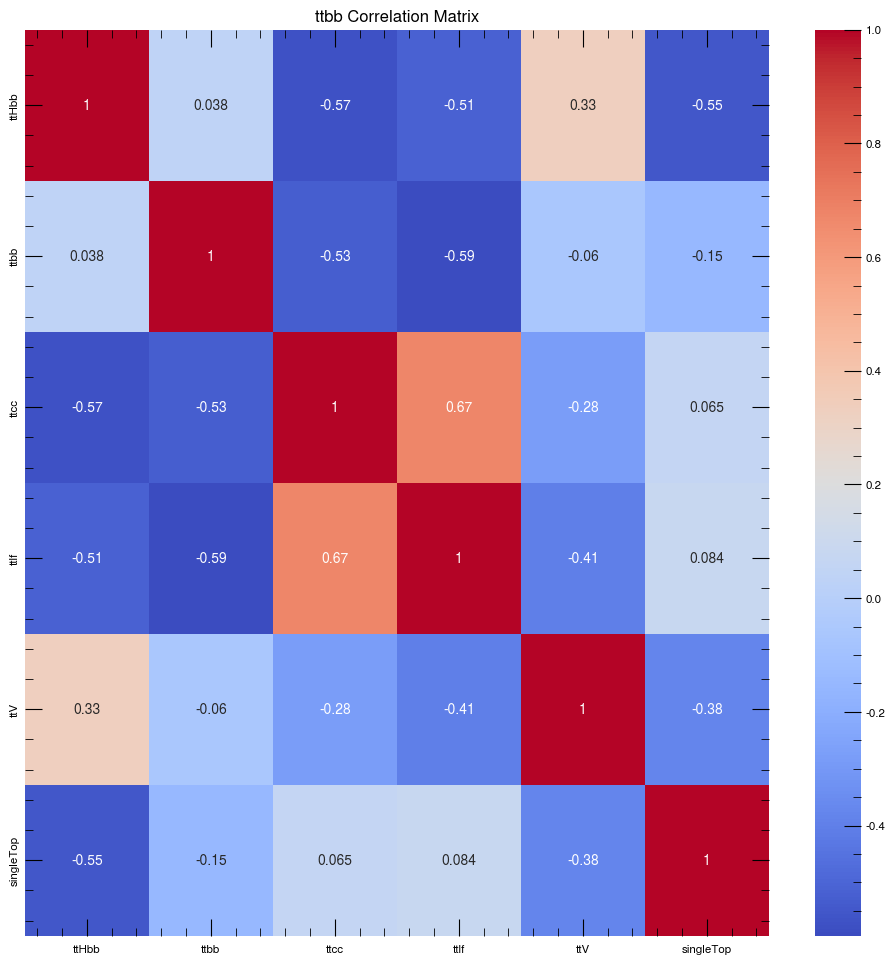

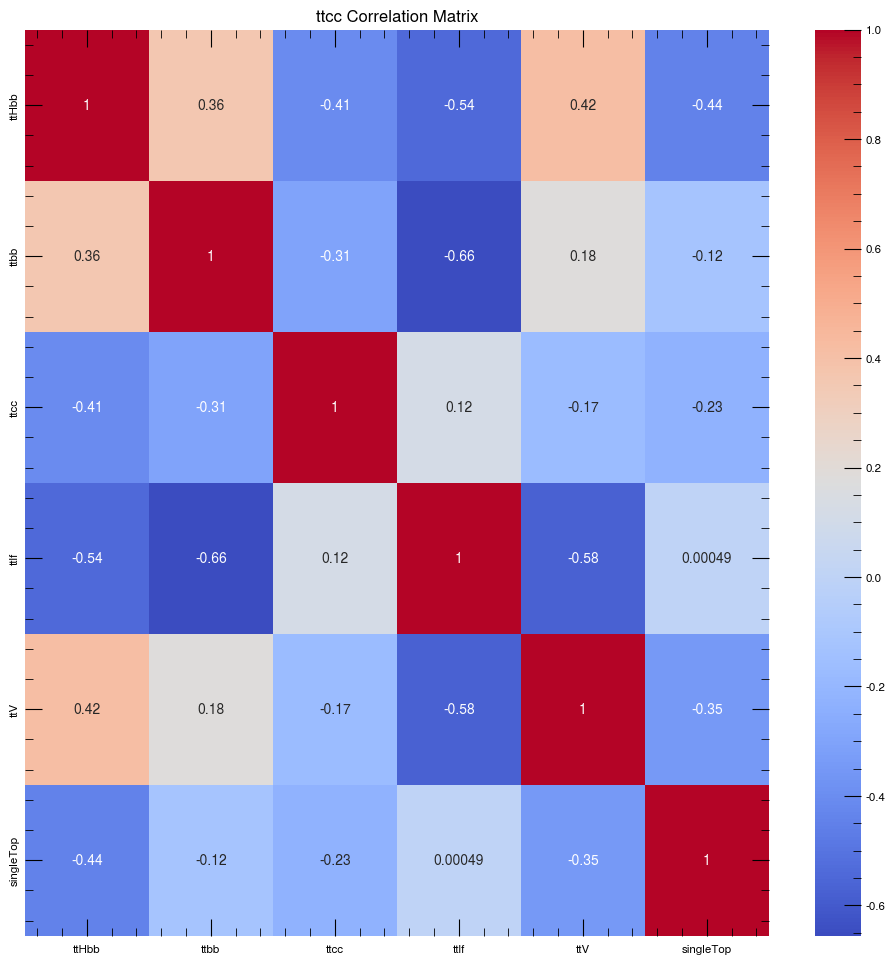

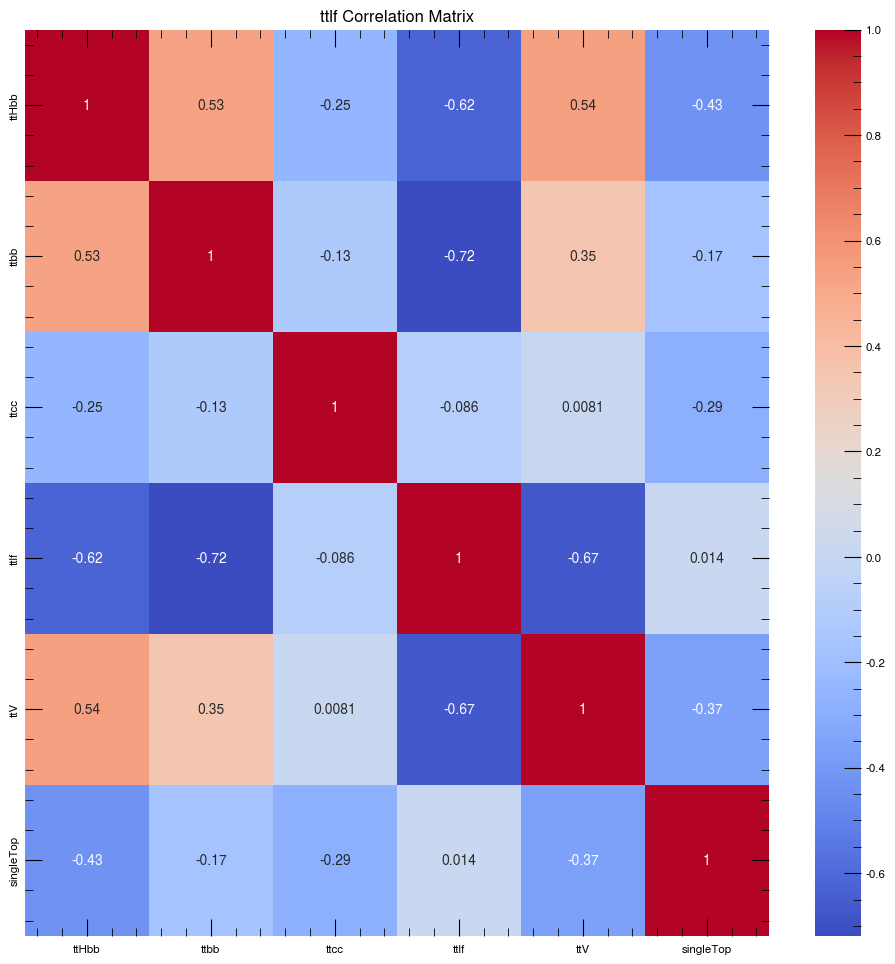

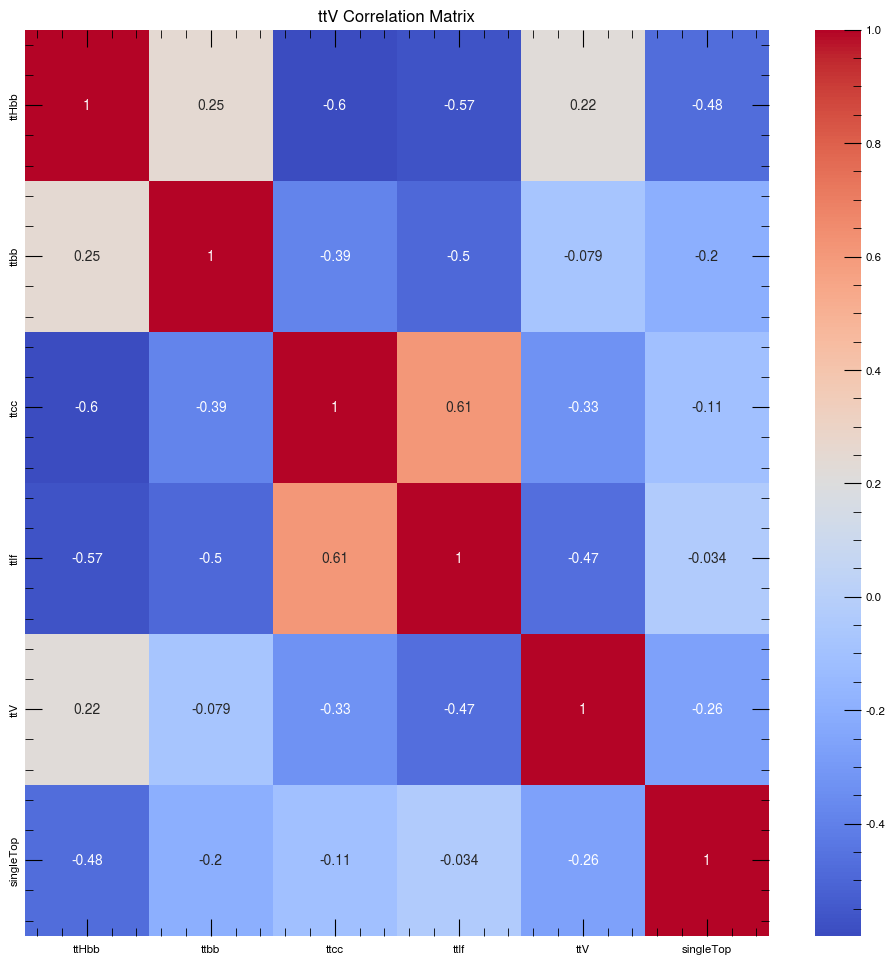

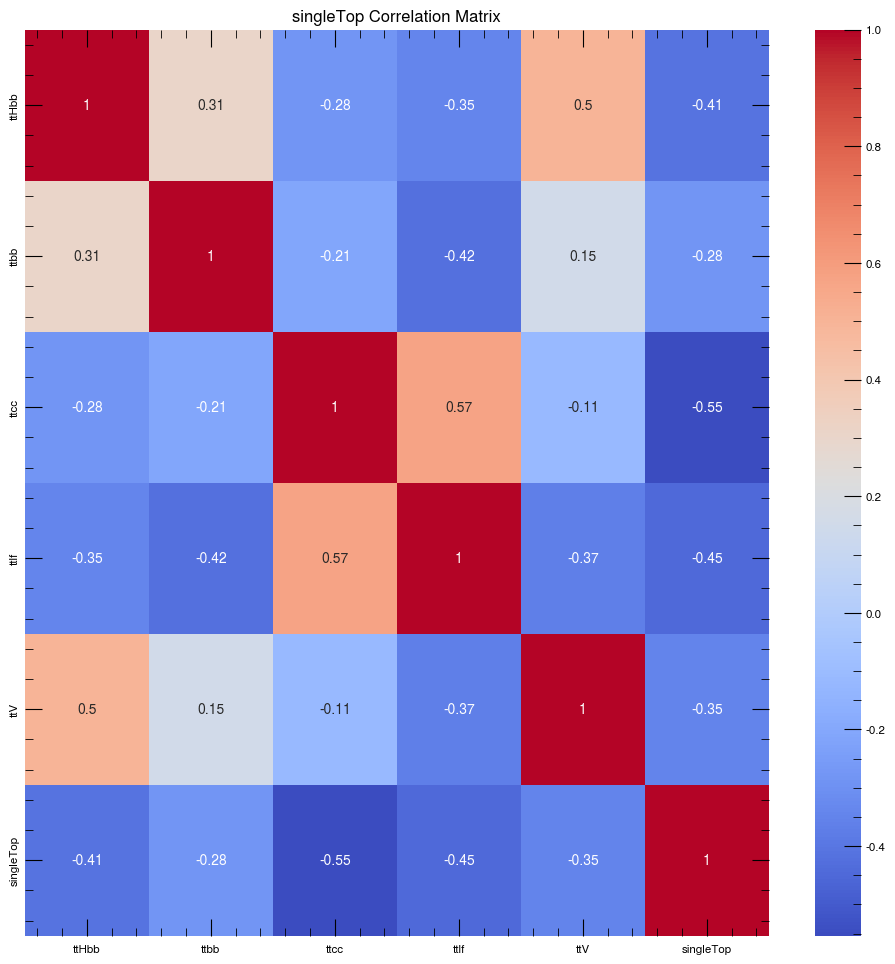

In [64]:
for label, class_index in labels.items():
    mask = y_true == class_index
    plot_correlation_matrix(cl_out[mask], plot_dir=out_folder, feature_names=labels.keys(), title=f"{label} Correlation Matrix")